# 05 · The onboarding tree: from a few answers to a preset

A new household answers a few questions; a decision tree walks those answers to one of the presets from notebook 04.
This replaces the app's current questionnaire, and the household is never asked about individual flows (CableLabs
guidance).

**Method: Smullen et al. 2020 (S20), adapted.** S20 profiles people with decision trees and chooses the number of
profiles by a budget of questions against accuracy. Here:

- **Input:** the household's answers to the candidate questions (notebook 02): realistic, concrete situations with
  examples (data type × purpose × where the data goes), 6 real-device flows and 3 household facts, each coded in its
  option order (no < depends < yes). Children are not a question (week 9: kept in the model, never surfaced).
- **Follow-up questions (week 9, the "second wizard"):** a hard cap of `TOTAL_QUESTIONS`; what the profiling tree
  does not use goes to follow-up situations on the cells the household's profile is least sure about.
- **Two ways to choose a leaf's preset:**
  - *cluster label*: the most common profile among the training households in that leaf (S20's profiling target);
  - *best match*: the preset whose rules best match the decisions of the training households in that leaf. This
    targets what matters (the household's own decisions) instead of the cluster label.
- **Measure:** on held-out households (5-fold cross-validation), how often the chosen preset's rules equal the
  household's own decisions, on all items and on the 52 real-device items; the number of questions asked (distinct
  questions on the household's path).
- **Baselines:** *one preset for everyone* (the overall majority, compressed to 15 rules the same way as notebook 04),
  and the *ceiling* (each household gets its own profile's preset, which no questionnaire can beat).

S20 used conditional inference trees (R); here scikit-learn's CART trees, limited by depth and a minimum leaf size, with
**balanced class weights** so small profiles are not ignored (without them, a profile of 4% of households is never
reached, even though a question identifies its households).

**A caveat:** the profiles were built from all households (notebook 03), including the ones held out here, so the
evaluation is slightly optimistic. With 5,000 households the effect is small.

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import KFold

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
DECISIONS = json.loads((ROOT / "decisions.json").read_text())   # team decisions, shared by notebooks 03-05
TEAM_K, TEAM_DEPTH = DECISIONS["presets_k"], DECISIONS["depth"]
items = pd.read_csv(DATA / "items.csv")
D = np.load(DATA / "decisions.npy")
answers = pd.read_csv(DATA / "answers.csv", dtype=str)
QUESTIONS = {q["id"]: q for q in json.loads((DATA / "questions.json").read_text())}
labels = pd.read_csv(DATA / "profiles" / "labels.csv")
CANDIDATES = [int(c[1:]) for c in labels.columns if c.startswith("k")]
PRESETS = {k: json.loads((DATA / "presets" / f"presets_k{k}.json").read_text()) for k in CANDIDATES}
PRESET_ITEMS = {k: np.load(DATA / "presets" / f"preset_items_k{k}.npy") for k in CANDIDATES}
real = items.in_corpus.to_numpy()
FIELDS = ["data_type", "purpose", "action", "source", "handling_context"]
cells = pd.read_csv(DATA / "cells.csv")
item_cell = items.merge(cells[["cell_id", "data_type", "purpose", "handling_context"]], on=["data_type", "purpose", "handling_context"], how="left").cell_id.to_numpy()
C_ALL = np.load(DATA / "decisions_cells.npy")                    # households × cells, acceptance 0..1 (what profiles are built on)
print(f"{len(answers):,} households, {len(QUESTIONS)} candidate questions, presets for k = {CANDIDATES}")

5,000 households, 114 candidate questions, presets for k = [2, 3, 4, 5, 6, 8, 10, 12, 16, 20, 24]


## Settings

In [2]:
DEPTHS = list(range(1, 13))         # a path asks at most this many questions
MIN_LEAF = 25                        # households per leaf, so no preset is chosen from a handful of people
TOTAL_QUESTIONS = 15                 # week 9: a hard cap on all questions, profiling plus follow-ups
MAX_QUESTIONS = 12                   # profiling may use at most this many, so every household gets at least 3 follow-ups
MIN_RECALL = 0.5                     # each profile's households must get their own preset at least this often
CLASS_WEIGHT = "balanced"            # weight small profiles up, so the tree spends splits on them too (otherwise a 4% profile is never reached)
FOLDS = 5
SEED = 0

## Answers as numbers

Each answer becomes its position in the question's option list (`data/questions.json`).

In [3]:
QIDS = list(QUESTIONS)
X = np.stack([answers[q].map({v: i for i, v in enumerate(QUESTIONS[q]["options"])}).to_numpy() for q in QIDS], axis=1).astype(float)
assert not np.isnan(X).any(), "an answer is not one of its question's options"
pd.DataFrame({"question": QIDS, "options (in order)": [" < ".join(QUESTIONS[q]["options"]) for q in QIDS]}).set_index("question").head(8)

,options (in order)
question,
devices,1-3 < 4-7 < 8-15 < 16+
household_size,1 < 2 < 3-4 < 5+
age_band,18-29 < 30-44 < 45-64 < 65+
cell_identifierData_coreFunctionality_householdContext,no < depends < yes
cell_identifierData_coreFunctionality_vendorContext,no < depends < yes
cell_identifierData_personalization_householdContext,no < depends < yes
cell_identifierData_personalization_vendorContext,no < depends < yes
cell_identifierData_personalization_thirdPartyContext,no < depends < yes


## Baseline: one preset for everyone

The overall majority decision per item, compressed into 15 rules with the same tree settings as notebook 04.

In [4]:
XI = pd.get_dummies(items[FIELDS]).to_numpy().astype(np.float32)
weights = np.where(real, 5.0, np.where(items.plausible, 1.0, 0.1))
def compress(decisions):
    return DecisionTreeClassifier(max_leaf_nodes=15, random_state=0).fit(XI, decisions, sample_weight=weights).predict(XI).astype(np.uint8)

folds = list(KFold(FOLDS, shuffle=True, random_state=SEED).split(X))
one = []
for tr, te in folds:
    preset = compress(np.array([np.bincount(col, minlength=5).argmax() for col in D[tr].T]))
    one.append({"match_all": (D[te] == preset).mean(), "match_real": (D[te][:, real] == preset[real]).mean()})
one = pd.DataFrame(one).mean()
one.round(3)

match_all     0.739
match_real    0.879
dtype: float64

## Trees for every k and depth

In [5]:
def questions_asked(tree, Xt):
    # Distinct questions on each household's path through the tree.
    path = tree.decision_path(Xt); feature = tree.tree_.feature
    return np.array([len({feature[n] for n in path.indices[path.indptr[i]:path.indptr[i + 1]] if feature[n] >= 0}) for i in range(len(Xt))])

def best_match(tree, Xtr, Dtr, preset_items):
    # For each leaf, the preset whose rules best match its training households' decisions.
    leaf = tree.apply(Xtr)
    return {int(L): int(np.argmax([(Dtr[leaf == L] == preset_items[c]).mean() for c in range(len(preset_items))])) for L in np.unique(leaf)}

def leaf_presets(tree, Xtr, Dtr, ytr, preset_items):
    # The chosen way of giving each leaf a preset (set after the choice below; defined here so later cells share it).
    if best_assignment == "best match":
        return best_match(tree, Xtr, Dtr, preset_items)
    leaf = tree.apply(Xtr)
    return {int(L): int(np.bincount(ytr[leaf == L], minlength=len(preset_items)).argmax()) for L in np.unique(leaf)}

# ---- Follow-up questions (week 9): the cells the household's profile is least sure about ----
SITUATION_COL = {}                                     # cell id -> column of X holding that situation's answer
for j, q in enumerate(QIDS):
    if "cell" in QUESTIONS[q]:
        cid = cells[(cells.data_type == QUESTIONS[q]["cell"]["data_type"]) & (cells.purpose == QUESTIONS[q]["cell"]["purpose"])
                    & (cells.handling_context == QUESTIONS[q]["cell"]["handling_context"])].cell_id.iloc[0]
        SITUATION_COL[int(cid)] = j
ASKABLE = np.array(sorted(SITUATION_COL))
CELL_ITEMS = {cid: np.where(item_cell == cid)[0] for cid in ASKABLE}

def follow_up_plan(tree, tr, ytr, k):
    """Per leaf: the askable cells ranked by how unsure the two most likely profiles are, and the leaf's path questions."""
    M = np.stack([C_ALL[tr][ytr == c].mean(axis=0) if (ytr == c).any() else np.full(C_ALL.shape[1], 0.5) for c in range(k)])
    leaf = tree.apply(X[tr]); plan = {}
    feature = tree.tree_.feature
    for L in np.unique(leaf):
        counts = np.bincount(ytr[leaf == L], minlength=k).astype(float)
        a, b = np.argsort(-counts)[:2]
        w = counts[[a, b]] / counts[[a, b]].sum()
        q = w[0] * M[a] + w[1] * M[b]                    # the leaf's best guess of each cell's acceptance
        unsure = 1 - np.abs(2 * q[ASKABLE] - 1)         # 1 = no idea, 0 = a strong preference
        row = np.where(leaf == L)[0][0]
        path = tree.decision_path(X[tr][row:row + 1]).indices
        on_path = {int(feature[n]) for n in path if feature[n] >= 0}
        plan[int(L)] = {"ranked": ASKABLE[np.argsort(-unsure, kind="stable")], "asked": on_path}
    return plan

def apply_follow_ups(given_items, rows, leaf_of_rows, plan):
    """Each household answers its leaf's top follow-ups within the budget; answers on the path apply for free.
    yes -> allow the cell's flows, no -> deny them, depends -> keep the preset."""
    out = given_items.copy(); used = np.zeros(len(rows))
    for L in np.unique(leaf_of_rows):
        sel = np.where(leaf_of_rows == L)[0]
        free = [cid for cid in plan[L]["ranked"] if SITUATION_COL[cid] in plan[L]["asked"]]
        budget = TOTAL_QUESTIONS - len(plan[L]["asked"])
        new = [cid for cid in plan[L]["ranked"] if SITUATION_COL[cid] not in plan[L]["asked"]][:max(budget, 0)]
        used[sel] = len(new)
        for cid in free + new:
            ans = X[rows[sel], SITUATION_COL[cid]]
            out[np.ix_(sel[ans == 2], CELL_ITEMS[cid])] = 1
            out[np.ix_(sel[ans == 0], CELL_ITEMS[cid])] = 0
    return out, used

rows = []
for k in CANDIDATES:
    y, P = labels[f"k{k}"].to_numpy(), PRESET_ITEMS[k]
    for depth in DEPTHS:
        for fold, (tr, te) in enumerate(folds):
            tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=MIN_LEAF, class_weight=CLASS_WEIGHT, random_state=SEED).fit(X[tr], y[tr])
            by_label = tree.predict(X[te])
            mapping = best_match(tree, X[tr], D[tr], P)
            by_match = np.array([mapping[int(L)] for L in tree.apply(X[te])])
            asked = questions_asked(tree, X[te])
            plan, te_leaf = follow_up_plan(tree, tr, y[tr], k), tree.apply(X[te])
            for how, chosen in [("cluster label", by_label), ("best match", by_match)]:
                after, used = apply_follow_ups(P[chosen], te, te_leaf, plan)
                rows.append({"k": k, "depth": depth, "fold": fold, "assignment": how,
                             "right profile": (chosen == y[te]).mean(),
                             "match_all": (P[chosen] == D[te]).mean(),
                             "match_real": (P[chosen][:, real] == D[te][:, real]).mean(),
                             "ceiling_real": (P[y[te]][:, real] == D[te][:, real]).mean(),
                             "questions (avg)": asked.mean(), "questions (max)": asked.max(), "presets used": len(set(chosen)),
                             "all presets used": len(set(chosen)) == k,
                             "lowest recall": min((chosen[y[te] == c] == c).mean() for c in range(k)),
                             "follow-ups (avg)": used.mean(), "questions total (avg)": asked.mean() + used.mean(),
                             "match_all_after": (after == D[te]).mean(), "match_real_after": (after[:, real] == D[te][:, real]).mean()})
cv = pd.DataFrame(rows).groupby(["assignment", "k", "depth"]).mean(numeric_only=True).drop(columns="fold")
cv.loc["best match"].round(3)

right profile  match_all  match_real  ceiling_real  questions (avg)  \
k  depth                                                                        
2  1              0.748      0.753       0.884         0.888            1.000   
   2              0.767      0.758       0.886         0.888            2.000   
   3              0.807      0.762       0.885         0.888            3.000   
   4              0.815      0.765       0.887         0.888            4.000   
   5              0.832      0.767       0.887         0.888            4.967   
...                 ...        ...         ...           ...              ...   
24 8              0.306      0.790       0.896         0.904            7.185   
   9              0.310      0.790       0.896         0.904            7.457   
   10             0.312      0.791       0.896         0.904            7.571   
   11             0.314      0.791       0.896         0.904            7.610   
   12             0.315      0.791       0.896         0.904            7.615   

          questions (max)  presets used  all presets used  lowest recall  \
k  depth                                                                   
2  1                  1.0           2.0               1.0          0.709   
   2                  2.0           2.0               1.0          0.624   
   3                  3.0           2.0               1.0          0.766   
   4                  4.0           2.0               1.0          0.732   
   5                  5.0           2.0               1.0          0.778   
...                   ...           ...               ...            ...   
24 8                  8.0          23.6               0.6          0.017   
   9                  9.0          23.6               0.6          0.027   
   10                10.0          23.8               0.8          0.039   
   11                10.6          23.8               0.8          0.039   
   12                10.8          23.8               0.8          0.039   

          follow-ups (avg)  questions total (avg)  match_all_after  \
k  depth                                                             
2  1                14.000                   15.0            0.771   
   2                13.000                   15.0            0.776   
   3                12.000                   15.0            0.779   
   4                11.000                   15.0            0.782   
   5                10.033                   15.0            0.783   
...                    ...                    ...              ...   
24 8                 7.815                   15.0            0.803   
   9                 7.543                   15.0            0.803   
   10                7.429                   15.0            0.804   
   11                7.390                   15.0            0.804   
   12                7.385                   15.0            0.804   

          match_real_after  
k  depth                    
2  1                 0.892  
   2                 0.893  
   3                 0.893  
   4                 0.894  
   5                 0.896  
...                    ...  
24 8                 0.907  
   9                 0.907  
   10                0.907  
   11                0.907  
   12                0.907  

[132 rows x 13 columns]

### Accuracy against the number of questions

Each point is one (k, depth). Higher and further left is better; the dashed lines are *one preset for everyone*.

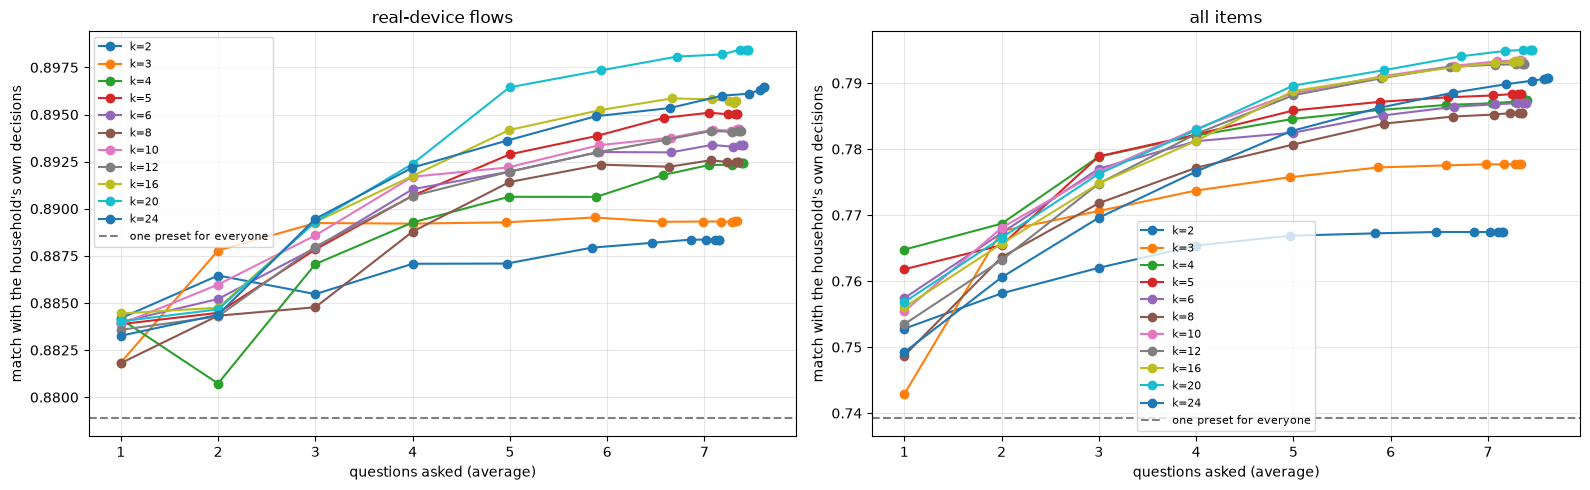

match_all               match_real               right profile  \
assignment best match cluster label best match cluster label    best match   
k                                                                            
2               0.765         0.763      0.887         0.885         0.815   
3               0.774         0.772      0.889         0.888         0.690   
4               0.782         0.779      0.889         0.883         0.600   
5               0.782         0.781      0.891         0.890         0.537   
6               0.781         0.778      0.891         0.886         0.492   
8               0.777         0.772      0.889         0.883         0.430   
10              0.783         0.781      0.892         0.889         0.374   
12              0.782         0.780      0.891         0.890         0.367   
16              0.781         0.776      0.892         0.888         0.291   
20              0.783         0.776      0.892         0.889         0.272   
24              0.777         0.763      0.892         0.886         0.204   

                          
assignment cluster label  
k                         
2                  0.815  
3                  0.687  
4                  0.587  
5                  0.545  
6                  0.489  
8                  0.420  
10                 0.388  
12                 0.375  
16                 0.309  
20                 0.289  
24                 0.239

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, metric, title in [(axes[0], "match_real", "real-device flows"), (axes[1], "match_all", "all items")]:
    for k in CANDIDATES:
        r = cv.loc[("best match", k)]
        ax.plot(r["questions (avg)"], r[metric], marker="o", label=f"k={k}")
    ax.axhline(one[metric], ls="--", color="grey", label="one preset for everyone")
    ax.set_xlabel("questions asked (average)"); ax.set_ylabel("match with the household's own decisions")
    ax.set_title(title); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
compare = cv.xs(4, level="depth")[["match_all", "match_real", "right profile"]].unstack(0)
compare.round(3)

## How many presets?

Context for the choice below. For each k: the best match within the question budget, the questions that takes (the fewest within
`DEPTH_TOLERANCE` of that best), what it adds over one preset for everyone, and how much of the gap to that k's ceiling
(every household given its own profile's preset) the questions close. A k is worth having only if the questions can
tell its presets apart: past some k, extra presets raise the ceiling but the tree cannot reach them.

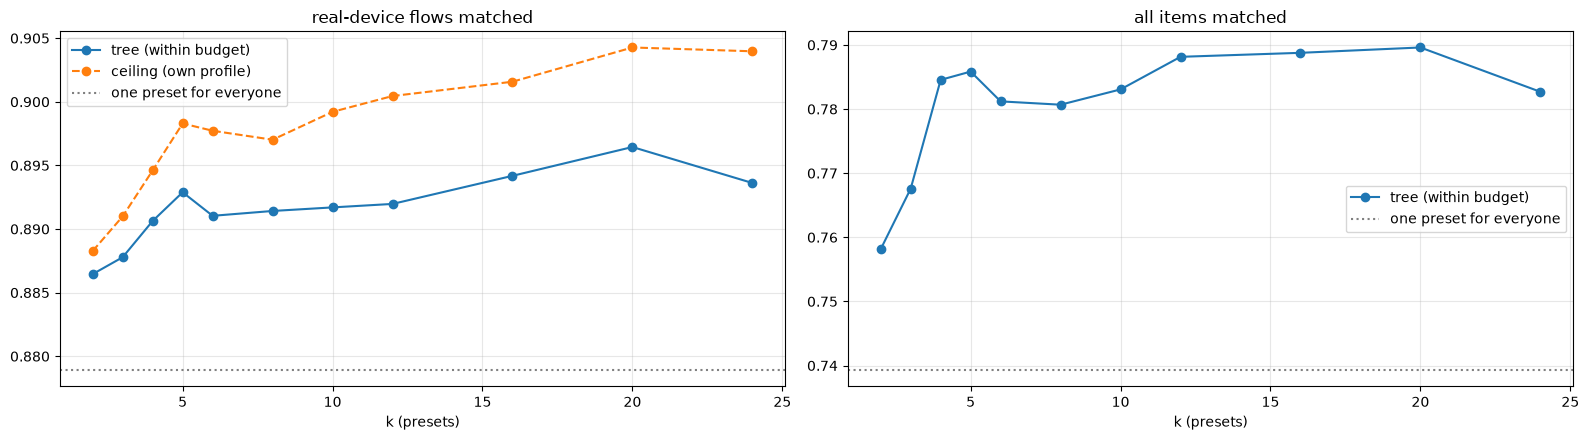

,depth,questions (avg),match real,match all,ceiling real,"gain over one preset, real (points)","gain over one preset, all (points)",share of the ceiling's gain reached
k,,,,,,,,
2,2,2.000,0.886,0.758,0.888,0.757,1.889,0.806
3,2,2.000,0.888,0.768,0.891,0.889,2.833,0.735
4,5,4.989,0.891,0.785,0.895,1.174,4.530,0.747
5,5,4.999,0.893,0.786,0.898,1.400,4.659,0.721
6,4,4.000,0.891,0.781,0.898,1.215,4.195,0.645
8,5,4.995,0.891,0.781,0.897,1.253,4.143,0.691
10,4,4.000,0.892,0.783,0.899,1.281,4.382,0.630
12,5,4.998,0.892,0.788,0.900,1.308,4.890,0.607
16,5,4.994,0.894,0.789,0.902,1.529,4.952,0.674


In [7]:
bm = cv.loc["best match"]
budget = bm[bm["questions (max)"] <= MAX_QUESTIONS]
how_many = []
for k, g in budget.groupby(level="k"):
    g = g.droplevel("k")
    pick = g[g.match_real >= g.match_real.max() - 0.003].sort_values("questions (avg)").iloc[0]
    how_many.append({"k": k, "depth": int(pick.name), "questions (avg)": pick["questions (avg)"],
                     "match real": pick.match_real, "match all": pick.match_all, "ceiling real": pick.ceiling_real,
                     "gain over one preset, real (points)": (pick.match_real - one.match_real) * 100,
                     "gain over one preset, all (points)": (pick.match_all - one.match_all) * 100,
                     "share of the ceiling's gain reached": (pick.match_real - one.match_real) / (pick.ceiling_real - one.match_real)})
how_many = pd.DataFrame(how_many).set_index("k")
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].plot(how_many.index, how_many["match real"], marker="o", label="tree (within budget)")
axes[0].plot(how_many.index, how_many["ceiling real"], marker="o", ls="--", label="ceiling (own profile)")
axes[0].axhline(one.match_real, color="grey", ls=":", label="one preset for everyone")
axes[0].set_title("real-device flows matched"); axes[0].set_xlabel("k (presets)"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(how_many.index, how_many["match all"], marker="o", label="tree (within budget)")
axes[1].axhline(one.match_all, color="grey", ls=":", label="one preset for everyone")
axes[1].set_title("all items matched"); axes[1].set_xlabel("k (presets)"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
how_many.round(3)

## Choose k and depth: well-defined profiles that the questions reach

The onboarding has to be **able to give every household its own profile's preset**. A (k, depth) is eligible only if:

1. **the profiles are well defined** (notebook 03, `quality.csv`): every profile stable (bootstrap Jaccard ≥ 0.75,
   Hennig 2007) and every pair of profiles different on at least 10% of items;
2. **every preset is used**, in every cross-validation fold;
3. **every profile is reached**: each profile's held-out households get their own preset at least `MIN_RECALL` of the
   time;
4. at most `MAX_QUESTIONS` questions on any path (a cap, not a target).

Among eligible pairs: the **highest match after follow-ups** on all items (the whole policy the household gets, once
its unused budget has gone to the cells its profile is least sure about); within 0.1 point of it, fewer questions in
total. A deeper tree places households better but leaves fewer follow-ups: this weighs the two (week 9). Both ways of choosing a leaf's preset are considered (*cluster label* and *best match*). Notebooks
03 and 04 read the choice from `decisions.json`, so this cell stops if the file disagrees (then update it and rerun
03–05).

well-defined k: [2, 3, 4]; eligible (k, depth, assignment): 59 of 264


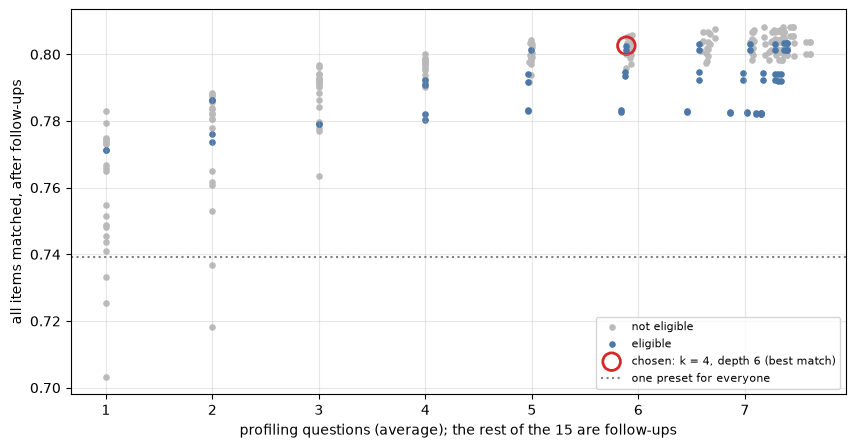

,assignment,k,depth,questions (avg),follow-ups (avg),match_real,match_all,match_real_after,match_all_after,lowest recall,all presets used,eligible
0,best match,2,1,1.000,14.000,0.884,0.753,0.892,0.771,0.709,True,True
1,best match,2,2,2.000,13.000,0.886,0.758,0.893,0.776,0.624,True,True
2,best match,2,3,3.000,12.000,0.885,0.762,0.893,0.779,0.766,True,True
3,best match,2,4,4.000,11.000,0.887,0.765,0.894,0.782,0.732,True,True
4,best match,2,5,4.967,10.033,0.887,0.767,0.896,0.783,0.778,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...
163,cluster label,4,8,7.044,7.956,0.889,0.785,0.899,0.801,0.556,True,True
164,cluster label,4,9,7.279,7.721,0.888,0.785,0.899,0.801,0.551,True,True
165,cluster label,4,10,7.371,7.629,0.888,0.785,0.899,0.801,0.547,True,True
166,cluster label,4,11,7.395,7.605,0.888,0.785,0.899,0.801,0.547,True,True


k                                                     4
depth                                                 6
assignment                                   best match
questions (avg)                                  5.8874
questions (max)                                     6.0
lowest recall                                  0.596076
match real-device flows                        0.890631
one preset for everyone                        0.878892
ceiling                                        0.894608
match all items                                0.785924
one preset (all items)                         0.739251
follow-ups (avg)                                 9.1126
questions in total (avg)                           15.0
match real-device flows, after follow-ups      0.900188
match all items, after follow-ups                0.8026
dtype: object

In [8]:
quality = pd.read_csv(DATA / "profiles" / "quality.csv").set_index("k")
WELL_DEFINED = set(quality.index[quality["well defined"]])
folds_ok = pd.DataFrame(rows).groupby(["assignment", "k", "depth"])["all presets used"].all()
table = cv.reset_index().assign(**{"all presets used": folds_ok.to_numpy()})
table["well defined"] = table.k.isin(WELL_DEFINED)
table["eligible"] = (table["well defined"] & table["all presets used"] & (table["lowest recall"] >= MIN_RECALL)
                     & (table["questions (max)"] <= MAX_QUESTIONS))
print(f"well-defined k: {sorted(WELL_DEFINED)}; eligible (k, depth, assignment): {int(table.eligible.sum())} of {len(table)}")
eligible = table[table.eligible]
assert len(eligible), "no (k, depth) reaches every well-defined profile: raise MAX_QUESTIONS or revisit notebook 03"
top = eligible.match_all_after.max()
pick = eligible[eligible.match_all_after >= top - 0.001].sort_values(["questions total (avg)", "k"]).iloc[0]
best_k, best_depth, best_assignment = int(pick.k), int(pick.depth), pick.assignment

fig, ax = plt.subplots(figsize=(10, 5))
for flag, colour, label in [(False, "#bbb", "not eligible"), (True, "#4c78a8", "eligible")]:
    s = table[table.eligible == flag]
    ax.scatter(s["questions (avg)"], s.match_all_after, s=14, color=colour, label=label)
ax.scatter([pick["questions (avg)"]], [pick.match_all_after], s=160, facecolors="none", edgecolors="#d62728", linewidths=2,
           label=f"chosen: k = {best_k}, depth {best_depth} ({best_assignment})")
ax.axhline(one.match_all, ls=":", color="grey", label="one preset for everyone")
ax.set_xlabel("profiling questions (average); the rest of the 15 are follow-ups"); ax.set_ylabel("all items matched, after follow-ups"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()
display(table[table.k.isin(WELL_DEFINED)].sort_values(["k", "assignment", "depth"])
        [["assignment", "k", "depth", "questions (avg)", "follow-ups (avg)", "match_real", "match_all", "match_real_after", "match_all_after",
          "lowest recall", "all presets used", "eligible"]].round(3))
assert (TEAM_K, TEAM_DEPTH) == (best_k, best_depth), (
    f"decisions.json has k = {TEAM_K}, depth = {TEAM_DEPTH}, but the choice is k = {best_k}, depth = {best_depth} "
    f"({best_assignment}): update decisions.json and rerun notebooks 03-05")
chosen = cv.loc[(best_assignment, best_k, best_depth)]
pd.Series({"k": best_k, "depth": best_depth, "assignment": best_assignment, "questions (avg)": chosen["questions (avg)"],
           "questions (max)": chosen["questions (max)"], "lowest recall": chosen["lowest recall"],
           "match real-device flows": chosen.match_real, "one preset for everyone": one.match_real, "ceiling": chosen.ceiling_real,
           "match all items": chosen.match_all, "one preset (all items)": one.match_all,
           "follow-ups (avg)": chosen["follow-ups (avg)"], "questions in total (avg)": chosen["questions total (avg)"],
           "match real-device flows, after follow-ups": chosen.match_real_after, "match all items, after follow-ups": chosen.match_all_after})

## Confusion matrix

For held-out households (same 5 folds): their own profile (rows) against the preset the tree gives them (columns),
as a share of each row. The diagonal is "the right preset". Off-diagonal mistakes matter less when the two presets
are similar, so the second matrix shows how much each pair of presets agrees on real-device flows.

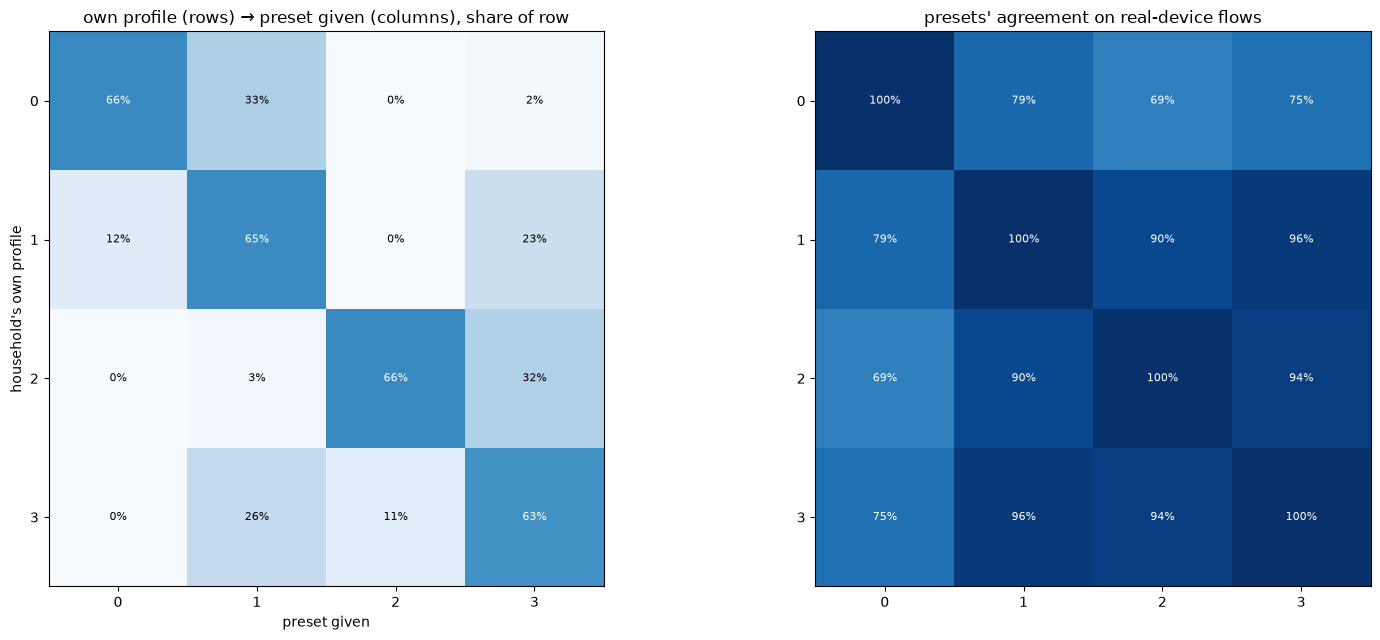

right preset for 64% of households; the preset given agrees with their own profile's preset on 97% of real-device flows on average


In [9]:
from sklearn.metrics import confusion_matrix
truth, given = [], []
for tr, te in folds:
    tr_tree = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=MIN_LEAF, class_weight=CLASS_WEIGHT, random_state=SEED).fit(X[tr], labels[f"k{best_k}"].to_numpy()[tr])
    mp = leaf_presets(tr_tree, X[tr], D[tr], labels[f"k{best_k}"].to_numpy()[tr], PRESET_ITEMS[best_k])
    truth += list(labels[f"k{best_k}"].to_numpy()[te]); given += [mp[int(L)] for L in tr_tree.apply(X[te])]
cm = confusion_matrix(truth, given, labels=range(best_k), normalize="true")
P_k = PRESET_ITEMS[best_k]
similar = np.array([[(P_k[a][real] == P_k[b][real]).mean() for b in range(best_k)] for a in range(best_k)])
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, m, title, fmt in [(axes[0], cm, "own profile (rows) → preset given (columns), share of row", "{:.0%}"),
                          (axes[1], similar, "presets' agreement on real-device flows", "{:.0%}")]:
    im = ax.imshow(m, cmap="Blues", vmin=0, vmax=1)
    for i in range(best_k):
        for j in range(best_k):
            ax.text(j, i, fmt.format(m[i, j]), ha="center", va="center", fontsize=8, color="white" if m[i, j] > 0.6 else "black")
    ax.set_xticks(range(best_k)); ax.set_yticks(range(best_k)); ax.set_title(title)
axes[0].set_xlabel("preset given"); axes[0].set_ylabel("household's own profile")
plt.tight_layout(); plt.show()
right = np.trace(confusion_matrix(truth, given, labels=range(best_k))) / len(truth)
cost = np.mean([similar[a, b] for a, b in zip(truth, given)])
print(f"right preset for {right:.0%} of households; the preset given agrees with their own profile's preset on {cost:.0%} of real-device flows on average")

Most households do not get exactly their own profile's preset, but the preset they get is usually a similar one: the
average agreement between "own" and "given" preset is high, which is why the match with the household's own decisions
stays close to the ceiling. Profiles the tree never assigns are ones its questions cannot tell apart from a neighbour.

## The chosen tree

Fit on all households; each leaf gets its best-matching preset.

In [10]:
y, P = labels[f"k{best_k}"].to_numpy(), PRESET_ITEMS[best_k]
tree = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=MIN_LEAF, class_weight=CLASS_WEIGHT, random_state=SEED).fit(X, y)
mapping = leaf_presets(tree, X, D, y, P)
names = {i: p["name"] for i, p in enumerate(PRESETS[best_k]["presets"])}
t = tree.tree_

def show(node=0, indent=""):
    if t.children_left[node] == -1:
        leaf_hh = int(t.n_node_samples[node])
        print(f"{indent}→ preset {mapping[node]}: {names[mapping[node]]}  ({leaf_hh} households)")
        return
    q = QIDS[t.feature[node]]; opts = QUESTIONS[q]["options"]; cut = int(np.floor(t.threshold[node]))
    print(f"{indent}{QUESTIONS[q]['text']}  [{q}]")
    print(f"{indent}  if {' / '.join(opts[:cut + 1])}:"); show(t.children_left[node], indent + "    ")
    print(f"{indent}  if {' / '.join(opts[cut + 1:])}:"); show(t.children_right[node], indent + "    ")
show()

A device sends how you use your devices (for example, when you switch the lights on, or what you watch on TV) to the company that made it, to send you alerts and messages (for example, a doorbell or smoke alarm notification). Would you allow this?  [cell_usageData_communicationsAndNotifications_vendorContext]
  if no / depends:
    A device's maker passes sensor readings (for example, the temperature, motion, or whether someone is home) on to other companies, such as advertising or analytics firms, to fix problems and update the device (for example, sending error reports). Would you allow this?  [cell_sensorData_diagnosticsAndMaintenance_thirdPartyContext]
      if no / depends:
        A device sends your account details (for example, your name, email address and account ID) to the company that made it, to keep your home and the device secure (for example, detecting a break-in or a hacked device). Would you allow this?  [cell_identifierData_security_vendorContext]
          if no / de

In [11]:
usage = pd.Series(questions := [QIDS[f] for f in t.feature if f >= 0]).value_counts()
leaf = tree.apply(X)
asked = questions_asked(tree, X)
print(f"questions used by the tree: {len(usage)} of {len(QIDS)}; households answer {asked.mean():.1f} on average (max {asked.max()})")
print("never used:", ", ".join(q for q in QIDS if q not in usage.index))
usage.rename("splits").to_frame()

questions used by the tree: 37 of 114; households answer 6.0 on average (max 6)
never used: devices, household_size, age_band, cell_identifierData_coreFunctionality_householdContext, cell_identifierData_coreFunctionality_vendorContext, cell_identifierData_personalization_vendorContext, cell_identifierData_personalization_thirdPartyContext, cell_identifierData_communicationsAndNotifications_vendorContext, cell_identifierData_security_householdContext, cell_identifierData_diagnosticsAndMaintenance_vendorContext, cell_identifierData_analyticsAndImprovement_vendorContext, cell_identifierData_advertisingAndMarketing_vendorContext, cell_identifierData_advertisingAndMarketing_thirdPartyContext, cell_profileData_coreFunctionality_householdContext, cell_profileData_personalization_householdContext, cell_profileData_personalization_vendorContext, cell_profileData_communicationsAndNotifications_vendorContext, cell_profileData_analyticsAndImprovement_vendorContext, cell_profileData_advertisingAndM

,splits
cell_locationData_diagnosticsAndMaintenance_thirdPartyContext,6
cell_deviceAndNetworkData_personalization_thirdPartyContext,4
cell_profileData_diagnosticsAndMaintenance_thirdPartyContext,3
cell_deviceAndNetworkData_analyticsAndImprovement_thirdPartyContext,2
cell_locationData_personalization_householdContext,2
cell_deviceAndNetworkData_advertisingAndMarketing_thirdPartyContext,2
cell_profileData_communicationsAndNotifications_householdContext,2
cell_identifierData_personalization_householdContext,2
cell_sensorData_advertisingAndMarketing_thirdPartyContext,2
cell_contentData_personalization_vendorContext,2


### Flowchart of the onboarding questions

The chosen tree as a flowchart: each box is a situation question (shortened to *data → where it goes, why*; the full
wording with examples is in `data/questions.json`), the arrows carry the answers, and each path ends in a preset at the
right, coloured from strict (red) to relaxed (green) by the share of flows it accepts. Saved as
`reports/onboarding-tree.svg`.

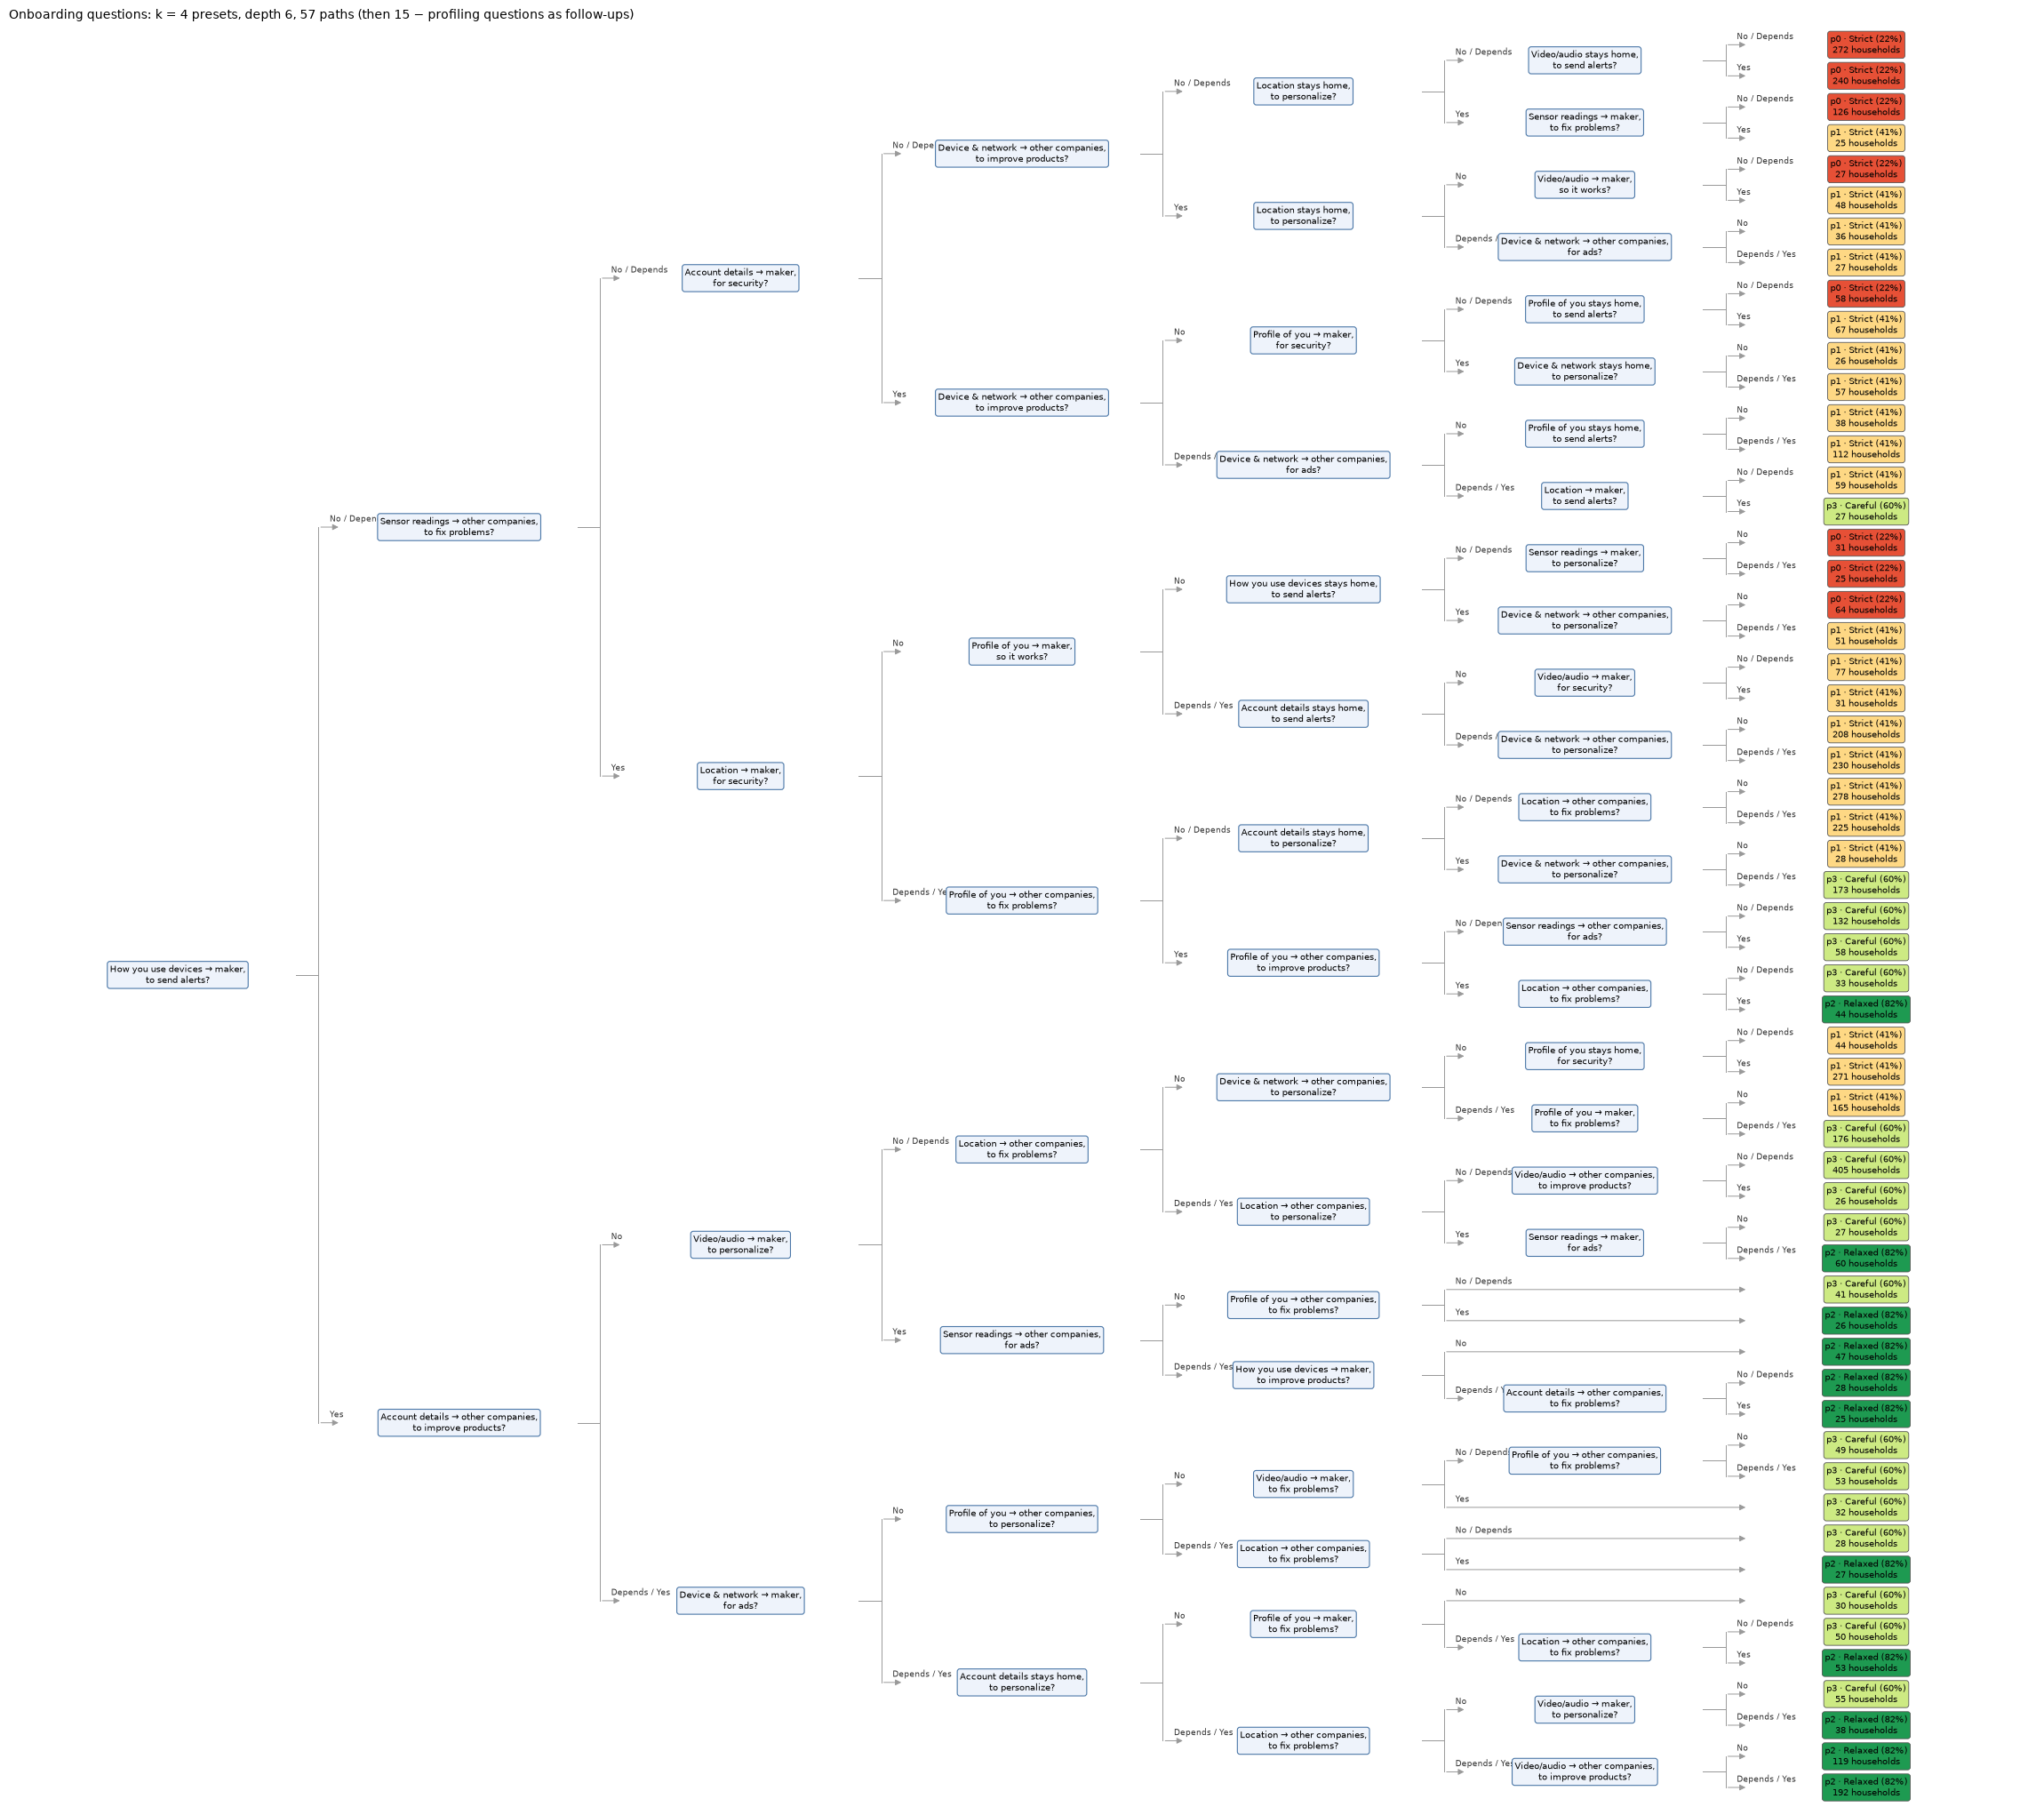

saved reports/onboarding-tree.svg: 57 paths, presets reached: [0, 1, 2, 3]


In [12]:
import matplotlib.colors as mcolors

SHORT_DATA = {"identifierData": "Account details", "profileData": "Profile of you", "sensorData": "Sensor readings",
              "contentData": "Video/audio", "locationData": "Location", "deviceAndNetworkData": "Device & network",
              "usageData": "How you use devices"}
SHORT_WHERE = {"householdContext": "stays home", "vendorContext": "→ maker", "thirdPartyContext": "→ other companies",
               "publicAudience": "→ public"}
SHORT_WHY = {"coreFunctionality": "so it works", "personalization": "to personalize", "communicationsAndNotifications": "to send alerts",
             "security": "for security", "diagnosticsAndMaintenance": "to fix problems", "analyticsAndImprovement": "to improve products",
             "legalCompliance": "for legal duties", "advertisingAndMarketing": "for ads"}
SHORT_ANSWER = {"no": "No", "depends": "Depends", "yes": "Yes", "with_limits": "With limits"}

def short_question(qid):
    q = QUESTIONS[qid]
    if "cell" not in q:
        return q["text"] if len(q["text"]) <= 44 else q["text"][:42] + "…"
    c = {f: v.split(":")[1] for f, v in q["cell"].items()}
    return f"{SHORT_DATA[c['data_type']]} {SHORT_WHERE[c['handling_context']]},\n{SHORT_WHY[c['purpose']]}?"

# Layout: leaves stacked top to bottom in the last column; a question sits halfway between its two children.
tt = tree.tree_
depth_of = {0: 0}
for node in range(tt.node_count):
    for child in (tt.children_left[node], tt.children_right[node]):
        if child != -1:
            depth_of[child] = depth_of[node] + 1
DEPTH_MAX = max(depth_of.values())
pos, next_row = {}, [0]
def layout(node):
    if tt.children_left[node] == -1:
        pos[node] = (DEPTH_MAX, next_row[0]); next_row[0] += 1
        return pos[node][1]
    mid = (layout(tt.children_left[node]) + layout(tt.children_right[node])) / 2
    pos[node] = (depth_of[node], mid)
    return mid
layout(0)

accept = {c: (P[c] != 0).mean() for c in range(best_k)}
short_names = {pc: PRESETS[best_k]["presets"][pc]["name"].split(" · ")[0] for pc in range(best_k)}
cmap, norm = plt.cm.RdYlGn, mcolors.Normalize(vmin=0.1, vmax=0.9)
n_leaves = next_row[0]
fig, ax = plt.subplots(figsize=(3.3 * (DEPTH_MAX + 1), max(6, 0.36 * n_leaves)))
for node, (col, row_y) in pos.items():   # names chosen so later cells' variables (y, q, d) are untouched
    if tt.children_left[node] == -1:
        continue
    qid_ = QIDS[tt.feature[node]]; opts_ = QUESTIONS[qid_]["options"]; cut_ = int(np.floor(tt.threshold[node]))
    for child, answers_ in ((tt.children_left[node], opts_[:cut_ + 1]), (tt.children_right[node], opts_[cut_ + 1:])):
        cd, cy = pos[child]
        x_out, x_turn, x_in = col + 0.42, col + 0.5, cd - 0.42      # right of the question, the elbow, left of the child
        ax.plot([x_out, x_turn, x_turn], [row_y, row_y, cy], color="#999", lw=0.7)
        ax.annotate("", xy=(x_in, cy), xytext=(x_turn, cy), arrowprops=dict(arrowstyle="-|>", color="#999", lw=0.7))
        ax.text(x_turn + 0.04, cy - 0.12, " / ".join(SHORT_ANSWER.get(a, a) for a in answers_), fontsize=6.5, color="#333", va="bottom")
for node, (col, row_y) in pos.items():
    if tt.children_left[node] == -1:
        pc = mapping[node]
        ax.text(col, row_y, f"p{pc} · {short_names[pc]} ({accept[pc]:.0%})\n{int(tt.n_node_samples[node])} households",
                ha="center", va="center", fontsize=7,
                bbox=dict(boxstyle="round,pad=0.3", fc=cmap(norm(accept[pc])), ec="#555", lw=0.6))
    else:
        ax.text(col, row_y, short_question(QIDS[tt.feature[node]]), ha="center", va="center", fontsize=7,
                bbox=dict(boxstyle="round,pad=0.3", fc="#EEF3FB", ec="#4c78a8", lw=0.8))
ax.set_xlim(-0.6, DEPTH_MAX + 0.6); ax.set_ylim(n_leaves - 0.4, -0.6); ax.axis("off")
ax.set_title(f"Onboarding questions: k = {best_k} presets, depth {best_depth}, {n_leaves} paths "
             f"(then {TOTAL_QUESTIONS} − profiling questions as follow-ups)", fontsize=10, loc="left")
plt.tight_layout()
(ROOT / "reports").mkdir(exist_ok=True)
fig.savefig(ROOT / "reports" / "onboarding-tree.svg", bbox_inches="tight")
plt.show()
print(f"saved reports/onboarding-tree.svg: {n_leaves} paths, presets reached: "
      f"{sorted({int(mapping[n]) for n in pos if tt.children_left[n] == -1})}")

## Follow-up questions (the "second wizard")

For the chosen tree, each leaf's follow-ups: the two most likely profiles of its households, and the situations ranked
from least to most sure. A household answers as many as `TOTAL_QUESTIONS` minus its profiling questions. In the app
these are the "help me refine my settings" wizard, which can also be rerun as a privacy checkup; each comes with why
it is asked ("households like you are split on this").

In [13]:
plan_all = follow_up_plan(tree, np.arange(len(X)), y, best_k)
leaf_all = tree.apply(X)
given_all = P[np.array([mapping[int(L)] for L in leaf_all])]
after_all, used_all = apply_follow_ups(given_all, np.arange(len(X)), leaf_all, plan_all)
print(f"follow-ups per household: {used_all.mean():.1f} on average (min {used_all.min():.0f}, max {used_all.max():.0f}); "
      f"questions in total: {asked.mean() + used_all.mean():.1f} on average, at most {int((asked + used_all).max())}")
print(f"match on all items (fitted on everyone): {(given_all == D).mean():.3f} before, {(after_all == D).mean():.3f} after follow-ups")
example_leaf = int(pd.Series(leaf_all).value_counts().index[0])
ex = plan_all[example_leaf]
budget = TOTAL_QUESTIONS - len(ex["asked"])
print(f"\nthe largest leaf ({int((leaf_all == example_leaf).sum())} households, preset {mapping[example_leaf]}): {budget} follow-ups, first five:")
for cid in [cid for cid in ex["ranked"] if SITUATION_COL[cid] not in ex["asked"]][:5]:
    print("  -", QUESTIONS[QIDS[SITUATION_COL[cid]]]["text"])

follow-ups per household: 9.0 on average (min 9, max 10); questions in total: 15.0 on average, at most 15
match on all items (fitted on everyone): 0.789 before, 0.806 after follow-ups

the largest leaf (405 households, preset 3): 9 follow-ups, first five:
  - A device sends your location (for example, your phone's location, to know when you are home or away) to the company that made it, to send you alerts and messages (for example, a doorbell or smoke alarm notification). Would you allow this?
  - A device sends your account details (for example, your name, email address and account ID) to the company that made it, to fix problems and update the device (for example, sending error reports). Would you allow this?
  - A device's maker passes device and network details (for example, the device's settings, your Wi-Fi network and IP address) on to other companies, such as advertising or analytics firms, to personalize what the device does or shows you (for example, heating that follows your 

## Robustness

1. **Without household facts.** Devices, household size, age and children are easy to answer but say little about
   preferences in the v3 households (S20 found some background facts useful). Same settings, the four facts removed.
2. **Noisier answers.** Real people answer less consistently than the synthetic households. At test time, each answer
   is replaced by a random option with probability *p*.

In [14]:
def evaluate(Xall, noise=0.0, rng=None):
    out = []
    for tr, te in folds:
        tr_tree = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=MIN_LEAF, class_weight=CLASS_WEIGHT, random_state=SEED).fit(Xall[tr], y[tr])
        mp = leaf_presets(tr_tree, Xall[tr], D[tr], y[tr], P)
        Xt = Xall[te].copy()
        if noise:
            flip = rng.random(Xt.shape) < noise
            n_opts = np.array([len(QUESTIONS[q]["options"]) for q in QIDS_USED])
            Xt[flip] = (rng.random(Xt.shape) * n_opts[None, :]).astype(int)[flip]
        chosen = np.array([mp[int(L)] for L in tr_tree.apply(Xt)])
        out.append({"match_real": (P[chosen][:, real] == D[te][:, real]).mean(), "match_all": (P[chosen] == D[te]).mean()})
    return pd.DataFrame(out).mean()

rng = np.random.default_rng(SEED)
QIDS_USED = QIDS
rows = {f"all {len(QIDS)} questions": evaluate(X)}
QIDS_USED = [q for q in QIDS if q not in ["devices", "household_size", "age_band", "children"]]
rows["without household facts"] = evaluate(X[:, [QIDS.index(q) for q in QIDS_USED]])
QIDS_USED = QIDS
for p in [0.1, 0.2, 0.3]:
    rows[f"answers {int(p * 100)}% random"] = evaluate(X, noise=p, rng=rng)
rows["one preset for everyone"] = one
robust = pd.DataFrame(rows).T
robust.round(3)

,match_all,match_real
all 114 questions,0.786,0.891
without household facts,0.786,0.891
answers 10% random,0.781,0.888
answers 20% random,0.774,0.886
answers 30% random,0.769,0.885
one preset for everyone,0.739,0.879


## Checks

In [15]:
checks = {
    "the chosen tree stays within the profiling budget": chosen["questions (max)"] <= MAX_QUESTIONS,
    "no household is asked more than the total cap": (asked + used_all).max() <= TOTAL_QUESTIONS,
    "follow-ups raise the match on all items": chosen.match_all_after > chosen.match_all + 0.005,
    "the profiles are well defined (stable, distinct)": best_k in WELL_DEFINED,
    "every preset is used in every fold": bool(folds_ok.loc[(best_assignment, best_k, best_depth)]),
    "every profile mostly gets its own preset": chosen["lowest recall"] >= MIN_RECALL,
    # Real-device flows are mostly core-functionality flows that nearly everyone accepts (data type × purpose fit), so one
    # preset already matches most of them; the onboarding must still beat it, by a point once follow-ups are in.
    "it beats one preset for everyone on real-device flows": chosen.match_real > one.match_real,
    "with follow-ups it beats one preset on real-device flows by a point": chosen.match_real_after > one.match_real + 0.01,
    "it beats one preset for everyone on all items": chosen.match_all > one.match_all + 0.01,
    "it does not exceed the ceiling (sanity)": chosen.match_real <= chosen.ceiling_real + 0.005,
    "without household facts it still beats one preset": robust.loc["without household facts", "match_real"] > one.match_real,
}
assert all(checks.values()), checks
pd.Series(checks, name="holds")

the chosen tree stays within the profiling budget                      True
no household is asked more than the total cap                          True
follow-ups raise the match on all items                                True
the profiles are well defined (stable, distinct)                       True
every preset is used in every fold                                     True
every profile mostly gets its own preset                               True
it beats one preset for everyone on real-device flows                  True
with follow-ups it beats one preset on real-device flows by a point    True
it beats one preset for everyone on all items                          True
it does not exceed the ceiling (sanity)                                True
without household facts it still beats one preset                      True
Name: holds, dtype: bool

## Compared with the studies

Allow/deny match (every *allow if* counted as allow) of the preset each held-out household is given, against what the
studies report for profile-based assistants:

| Study | Reported |
| --- | --- |
| S20 §4.3 | profiles reach 75–90% allow/deny accuracy; about 78–83% within 30–40 interactions for 36 apps |
| Liu et al. 2016 | at most 5 questions; 78.7% of the assistant's recommendations were kept by real users |

Liu's number is what people *kept*, not a match with stated preferences, so it is a rough reference only.

In [16]:
ad = []
for tr, te in folds:
    tr_tree = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=MIN_LEAF, class_weight=CLASS_WEIGHT, random_state=SEED).fit(X[tr], y[tr])
    mp = leaf_presets(tr_tree, X[tr], D[tr], y[tr], P)
    given_items = P[np.array([mp[int(L)] for L in tr_tree.apply(X[te])])]
    ad.append({"all items": ((given_items != 0) == (D[te] != 0)).mean(),
               "real-device flows": ((given_items[:, real] != 0) == (D[te][:, real] != 0)).mean()})
ad = pd.DataFrame(ad).mean()
study = {"allow/deny match within S20's 75-90% (all items)": 0.75 <= ad["all items"] <= 0.90,
         # Real-device flows are mostly core-functionality flows nearly everyone accepts, so only S20's lower bound applies.
         "allow/deny match at least S20's 75% (real-device flows)": ad["real-device flows"] >= 0.75}
print(f"allow/deny match: all items {ad['all items']:.1%}, real-device flows {ad['real-device flows']:.1%}, "
      f"with {chosen['questions (avg)']:.1f} questions on average (Liu 2016: 78.7% kept, at most 5 questions)")
assert all(study.values()), study
pd.Series(study, name="holds")

allow/deny match: all items 80.9%, real-device flows 90.2%, with 5.9 questions on average (Liu 2016: 78.7% kept, at most 5 questions)


allow/deny match within S20's 75-90% (all items)           True
allow/deny match at least S20's 75% (real-device flows)    True
Name: holds, dtype: bool

## What this means

- **k = 4 at depth 6, best match** (`decisions.json`), with presets of 30 rules (the knee of notebook 04's sweep, instead
  of a fixed 15): only k = 2–4 give well-defined profiles (notebook 03), and among the trees that reach all of them this
  one matches best once follow-ups are in. With 15-rule presets the choice was k = 3: the coarser rules hid what a
  fourth preset adds.
- **15 questions in total**: 5.9 profiling situations on average (at most 6) and 9 follow-ups on the cells the
  household's two most likely profiles are least sure about. Match on all items: 73.9% for one preset for everyone,
  78.6% after profiling, 80.3% after follow-ups; on real-device flows 87.9%, 89.1% and 90.0%.
- 64% of households get exactly their own profile's preset, and every profile is reached (the worst at 60%).
- **The profiles are mostly strictness levels** (they accept 22%, 41%, 60% and 82% of flows), with purpose differences
  on top. The concern types (notebook 02) are picked up by the follow-ups, which ask about single data type × purpose
  situations, rather than by the profiles.
- The allow/deny match on all items (81%) is inside S20's range for profile-based assistants; on real-device flows
  (90%) it is above it, because those flows are mostly core functionality that nearly everyone accepts.

## Save

`data/onboarding_tree.json`: the question nodes (with question text and which answers go which way) and the leaves
(with the chosen preset), for notebook 07 to export to the app.

In [17]:
def node_json(node):
    if t.children_left[node] == -1:
        p = PRESETS[best_k]["presets"][mapping[node]]
        follow = [QIDS[SITUATION_COL[cid]] for cid in plan_all[int(node)]["ranked"] if SITUATION_COL[cid] not in plan_all[int(node)]["asked"]]
        budget = TOTAL_QUESTIONS - len(plan_all[int(node)]["asked"])
        return {"preset": p["id"], "preset_name": p["name"], "households": int(t.n_node_samples[node]),
                "follow_up_budget": int(budget), "follow_ups": follow[:budget]}
    q = QIDS[t.feature[node]]; opts = QUESTIONS[q]["options"]; cut = int(np.floor(t.threshold[node]))
    return {"question": q, "text": QUESTIONS[q]["text"],
            "branches": [{"answers": opts[:cut + 1], "next": node_json(t.children_left[node])},
                         {"answers": opts[cut + 1:], "next": node_json(t.children_right[node])}]}

(DATA / "onboarding_tree.json").write_text(json.dumps({
    "k": int(best_k), "depth": int(best_depth), "assignment": best_assignment, "presets_file": f"presets/presets_k{best_k}.json",
    "questions_avg": round(float(asked.mean()), 2), "questions_max": int(asked.max()),
    "match_real_cv": round(float(chosen.match_real), 3), "match_all_cv": round(float(chosen.match_all), 3),
    "one_preset_real_cv": round(float(one.match_real), 3), "one_preset_all_cv": round(float(one.match_all), 3), "total_questions_cap": TOTAL_QUESTIONS,
    "match_all_after_follow_ups_cv": round(float(chosen.match_all_after), 3), "match_real_after_follow_ups_cv": round(float(chosen.match_real_after), 3),
    "root": node_json(0)}, indent=2) + "\n")
print("saved data/onboarding_tree.json")

saved data/onboarding_tree.json
